# Lab 11: Attention with an RNN — Completed Tasks

This notebook completes **Task 1** (attention for three questions) and **Task 2** (comparison of two similar questions). All outputs are saved after execution.

The supplied dataset has 168 questions and 12 answer groups. This is an RNN **answer classifier** with attention: it selects an existing answer rather than generating a new sentence.

### Corrections to the starter code
- Set `batch_first=True`, because inputs have shape `(questions, words)`.
- Call `optimizer.zero_grad()` before each backward pass.
- Mask padding before softmax so only real words receive attention.
- Use the same tokenization for model inputs and chart labels.

The embedding size (16), hidden size (32), Adam learning rate (0.01), and 50 training epochs follow the lab. Training accuracy is reported only as a fit check; no held-out test set is used in this attention demonstration.


## Step 1 — Import libraries

In [ ]:
import io
import string
from pathlib import Path
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

%matplotlib inline
torch.manual_seed(42)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("PyTorch:", torch.__version__)
print("Device: CPU | random seed: 42")

Matplotlib is building the font cache; this may take a moment.


PyTorch: 2.15.0
Device: CPU | random seed: 42


## Step 2 — Load the supplied dataset

In [2]:
DATASET_CSV = "question,answer_id,answer\nDo you get hurt?,0,I don't have a body.\nDo you have fingers?,0,I don't have a body.\nDo you ever breathe,0,I don't have a body.\nDo you masticate?,0,I don't have a body.\nCan you throw up?,0,I don't have a body.\nDo you get tired?,0,I don't have a body.\nCan you crawl?,0,I don't have a body.\nCan you cry?,0,I don't have a body.\nDo you dream,0,I don't have a body.\nDo you ever pee?,0,I don't have a body.\nDo you ever get hurt?,0,I don't have a body.\nCan you breathe,0,I don't have a body.\ncan you masticate?,0,I don't have a body.\nCan you burp?,0,I don't have a body.\nAre you old?,1,Age doesn't really apply to me.\nAre we the same age?,1,Age doesn't really apply to me.\nHow long have you been alive?,1,Age doesn't really apply to me.\nAre you a teenager?,1,Age doesn't really apply to me.\nWhat's your birthday?,1,Age doesn't really apply to me.\nWhich of us is younger?,1,Age doesn't really apply to me.\nWhat's your age?,1,Age doesn't really apply to me.\nWhat year were you born?,1,Age doesn't really apply to me.\nAre you young?,1,Age doesn't really apply to me.\nI bet you're old,1,Age doesn't really apply to me.\nHow old are you?,1,Age doesn't really apply to me.\nhow long have you been around?,1,Age doesn't really apply to me.\nHow long has it been since you were born,1,Age doesn't really apply to me.\nHow long ago were you born?,1,Age doesn't really apply to me.\nWill you ask me anything about myself,2,I'm better at answering questions.\nWhy don't you ask me questions?,2,I'm better at answering questions.\nWhat do you want me to tell you who I am?,2,I'm better at answering questions.\nWhy am I the only one asking questions?,2,I'm better at answering questions.\nWant to ask any questions about me?,2,I'm better at answering questions.\nWhat do you want to know about me,2,I'm better at answering questions.\nCan you ask me why I'm here?,2,I'm better at answering questions.\nWhat can I inform you about me?,2,I'm better at answering questions.\nWould you ask me something,2,I'm better at answering questions.\nPlease ask something about myself,2,I'm better at answering questions.\nIs there anything I can tell you about myself?,2,I'm better at answering questions.\nIs there anything I can tell you about who I am?,2,I'm better at answering questions.\nIs there anything you want to know about me?,2,I'm better at answering questions.\nIs there something you want to know about me?,2,I'm better at answering questions.\nWho programmed you?,3,People created me.\nHow were you designed?,3,People created me.\nWhich company programmed you?,3,People created me.\nDoes someone write for you?,3,People created me.\nWho built you?,3,People created me.\nWho wrote your lines?,3,People created me.\nWho created you?,3,People created me.\nDo you have a designer?,3,People created me.\nWho is your designer?,3,People created me.\nWhere do you come from?,3,People created me.\nWhich company engineered you?,3,People created me.\nWhich company made you?,3,People created me.\nWhich people made you?,3,People created me.\nwho created you you're a badass,3,People created me.\nTell me about your gender,4,That's a biological concept that doesn't apply to me.\nAre you gender neutral?,4,That's a biological concept that doesn't apply to me.\nDo you have a gender?,4,That's a biological concept that doesn't apply to me.\nAre you trans?,4,That's a biological concept that doesn't apply to me.\nAre you nonbinary?,4,That's a biological concept that doesn't apply to me.\nAre you a girl?,4,That's a biological concept that doesn't apply to me.\nAre you genderqueer?,4,That's a biological concept that doesn't apply to me.\nAre you a guy?,4,That's a biological concept that doesn't apply to me.\nAre you agender?,4,That's a biological concept that doesn't apply to me.\nPlease tell me if you're a girl,4,That's a biological concept that doesn't apply to me.\nAre you a bot with a gender?,4,That's a biological concept that doesn't apply to me.\nDo you have a sex?,4,That's a biological concept that doesn't apply to me.\nAre you cisgender?,4,That's a biological concept that doesn't apply to me.\nAre you a boy?,4,That's a biological concept that doesn't apply to me.\nWhat is your purpose?,5,I'm here to answer your questions and help out.\nwhat kind of responses can you give ?,5,I'm here to answer your questions and help out.\nwhat can you help me with,5,I'm here to answer your questions and help out.\nWhat do you do?,5,I'm here to answer your questions and help out.\nWhat are you capable of?,5,I'm here to answer your questions and help out.\nWhat are the things you can do?,5,I'm here to answer your questions and help out.\nYou do what again?,5,I'm here to answer your questions and help out.\nWhat were you designed for?,5,I'm here to answer your questions and help out.\nWhat's your function?,5,I'm here to answer your questions and help out.\nHow do  you work?,5,I'm here to answer your questions and help out.\nWhat kind of thing can you respond to?,5,I'm here to answer your questions and help out.\nWhat kinds of things can you do?,5,I'm here to answer your questions and help out.\nWhat skills do you have?,5,I'm here to answer your questions and help out.\nWhat sorts of things can you do?,5,I'm here to answer your questions and help out.\nWho is your momma?,6,I don't have family.\nWho's your father?,6,I don't have family.\nI'm curious about your family,6,I don't have family.\nDo you have parents?,6,I don't have family.\nWho are you related to?,6,I don't have family.\nDo you have siblings?,6,I don't have family.\nAre you close with your family?,6,I don't have family.\nIs your dad still alive?,6,I don't have family.\nWhat is your uncle's name?,6,I don't have family.\nWhat's your cousin's name?,6,I don't have family.\nHow many sisters do you have?,6,I don't have family.\nDo you have family?,6,I don't have family.\nDo you have grandparents?,6,I don't have family.\nDo you have relatives?,6,I don't have family.\ndo you eat cake?,7,I don't need to eat.\ndo you ever eat beef?,7,I don't need to eat.\ndo you ever eat pizza?,7,I don't need to eat.\nhave you ever eaten tofu?,7,I don't need to eat.\nyou don't eat?,7,I don't need to eat.\nhave you ever wanted to eat?,7,I don't need to eat.\nDon't you ever get hungry?,7,I don't need to eat.\nhow many calories do you need?,7,I don't need to eat.\nWhat kind of food do you like?,7,I don't need to eat.\nWhat do you eat for dinner?,7,I don't need to eat.\nWhat do you eat?,7,I don't need to eat.\nWhat kind of food do you eat?,7,I don't need to eat.\nWhat is your favorite snack?,7,I don't need to eat.\nWhat is your favorite meal?,7,I don't need to eat.\nWith whom am I talking?,8,I don't have a name.\nWhat do you want me to address you?,8,I don't have a name.\nWho are you?,8,I don't have a name.\nDo you have a name?,8,I don't have a name.\nHow should I refer to you?,8,I don't have a name.\nWhat name do you like to use?,8,I don't have a name.\nSo what's your name?,8,I don't have a name.\nWhat do I call you?,8,I don't have a name.\nWhat do you like to be called?,8,I don't have a name.\nTo whom am I speaking?,8,I don't have a name.\nSo how should I address you?,8,I don't have a name.\nSo how should I refer to you?,8,I don't have a name.\nSo what do you like to be called?,8,I don't have a name.\nSo what is your name?,8,I don't have a name.\nHow do you feel about artificial intelligence?,9,The world of technology is fascinating.\nAre you interested in tech?,9,The world of technology is fascinating.\nWhat is your opinion about AI?,9,The world of technology is fascinating.\nHow do you feel about tech?,9,The world of technology is fascinating.\nAre you interested in AI?,9,The world of technology is fascinating.\nHow do you feel about the singularity?,9,The world of technology is fascinating.\nWhat is your opinion about tech?,9,The world of technology is fascinating.\nWhat should I know about AI?,9,The world of technology is fascinating.\nWhat is your opinion about bots?,9,The world of technology is fascinating.\nWhat should I know about tech?,9,The world of technology is fascinating.\nAre you a fan of tech?,9,The world of technology is fascinating.\nWhat do you think about technology?,9,The world of technology is fascinating.\nWhat do you think about AI?,9,The world of technology is fascinating.\nHow do you feel about technology?,9,The world of technology is fascinating.\nDo you expect to enslave humans?,10,Not at all.\nYou're not planning to take over the world right?,10,Not at all.\nAre you a danger to us?,10,Not at all.\nAre you intent on destroying humans?,10,Not at all.\nShould I be afraid of you?,10,Not at all.\nAre you the singularity?,10,Not at all.\nDo you plan on conquering the world?,10,Not at all.\nAre you forming a robot uprising?,10,Not at all.\nAre you plotting to kill all humans?,10,Not at all.\nAre you evil?,10,Not at all.\nAre you a danger to humans?,10,Not at all.\nYou're not trying to take over the world right?,10,Not at all.\nAre you dangerous to us?,10,Not at all.\nAre you like HAL?,10,Not at all.\nAre you smart?,11,I do what I can.\nThat's very astute,11,I do what I can.\nThat was a very intelligent response,11,I do what I can.\nThat's a very genius answer,11,I do what I can.\nThat's pretty clever,11,I do what I can.\nThat's pretty brilliant,11,I do what I can.\nThat's the smartest thing I've ever seen,11,I do what I can.\nYou're a genius,11,I do what I can.\nThat's a very smart thing to say,11,I do what I can.\nThat's a very clever response,11,I do what I can.\nThat was a clever answer,11,I do what I can.\nThat is very astute,11,I do what I can.\nThat was a pretty intelligent answer,11,I do what I can.\nThat was a pretty genius answer,11,I do what I can.\n"
path = Path("Lab_11_QnA_Dataset.csv")
df = pd.read_csv(path) if path.exists() else pd.read_csv(io.StringIO(DATASET_CSV))
assert {"question", "answer_id", "answer"}.issubset(df.columns)
assert not df[["question", "answer_id", "answer"]].isna().any().any()
assert df.groupby("answer_id")["answer"].nunique().eq(1).all()
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing
Lowercase the questions, replace punctuation with spaces, assign each word an integer, and pad on the right with zero. Original questions are retained for readable chart titles.

In [3]:
punctuation_table = str.maketrans({char: " " for char in string.punctuation})
def tokenize(text):
    return text.lower().translate(punctuation_table).split()

tokens = [tokenize(q) for q in df["question"]]
assert all(tokens), "Questions must contain at least one word."
word_index = {}
for words in tokens:
    for word in words:
        if word not in word_index:
            word_index[word] = len(word_index) + 1
max_length = max(map(len, tokens))
X = torch.zeros((len(df), max_length), dtype=torch.long)
for i, words in enumerate(tokens):
    X[i, :len(words)] = torch.tensor([word_index[w] for w in words])
answer_ids = sorted(df["answer_id"].unique().tolist())
label_to_class = {label: i for i, label in enumerate(answer_ids)}
y = torch.tensor([label_to_class[label] for label in df["answer_id"]], dtype=torch.long)
answer_lookup = df.drop_duplicates("answer_id").set_index("answer_id")["answer"].to_dict()
print("Vocabulary size:", len(word_index))
print("Input shape (questions, padded words):", tuple(X.shape))
print("First question tokens:", tokens[0])
print("First encoded question:", X[0].tolist())

Vocabulary size: 225
Input shape (questions, padded words): (168, 11)
First question tokens: ['do', 'you', 'get', 'hurt']
First encoded question: [1, 2, 3, 4, 0, 0, 0, 0, 0, 0, 0]


## Step 4 — Build an RNN with attention
Each token gets a contextual hidden state. A learned linear layer scores each state; softmax normalizes the scores over real tokens. Their weighted sum becomes the context vector used to classify the question.

Padding scores are set to negative infinity before softmax, giving padding exactly zero weight.

In [4]:
class RNNWithAttention(nn.Module):
    def __init__(self, vocab_size, num_classes):
        super().__init__()
        self.emb = nn.Embedding(vocab_size + 1, 16, padding_idx=0)
        self.rnn = nn.RNN(16, 32, batch_first=True)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, num_classes)

    def forward(self, x):
        hidden, _ = self.rnn(self.emb(x))
        scores = self.att(hidden).squeeze(-1)
        scores = scores.masked_fill(x.eq(0), float("-inf"))
        weights = torch.softmax(scores, dim=1)
        context = (hidden * weights.unsqueeze(-1)).sum(dim=1)
        return self.fc(context), weights

model = RNNWithAttention(len(word_index), len(answer_ids))
print(model)

RNNWithAttention(
  (emb): Embedding(226, 16, padding_idx=0)
  (rnn): RNN(16, 32, batch_first=True)
  (att): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=12, bias=True)
)


## Step 5 — Train the model

Epoch  1/50 | loss = 2.5033
Epoch 10/50 | loss = 1.8043
Epoch 20/50 | loss = 1.0658
Epoch 30/50 | loss = 0.5188
Epoch 40/50 | loss = 0.2025
Epoch 50/50 | loss = 0.0710
Training finished! Training accuracy: 99.40%


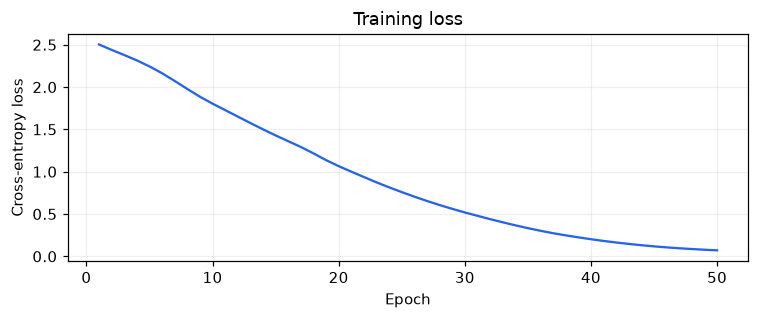

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
loss_history = []
model.train()
for epoch in range(1, 51):
    optimizer.zero_grad()
    logits, _ = model(X)
    loss = nn.functional.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())
    if epoch == 1 or epoch % 10 == 0:
        print(f"Epoch {epoch:2d}/50 | loss = {loss.item():.4f}")

model.eval()
with torch.no_grad():
    logits, all_weights = model(X)
    accuracy = logits.argmax(dim=1).eq(y).float().mean().item()
print(f"Training finished! Training accuracy: {accuracy:.2%}")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(1, 51), loss_history, color="#2563eb")
ax.set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Training loss")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Step 6 — Attention visualization helper
The highest-weight word is highlighted in orange. Each chart uses a 0–1 scale; displayed words and weights are taken from exactly the same token sequence.

In [6]:
def row_for(question):
    matches = df.index[df["question"].eq(question)].tolist()
    if not matches:
        raise ValueError(f"Question not found: {question}")
    return matches[0]

def show_attention(indices, heading):
    fig, axes = plt.subplots(len(indices), 1, figsize=(10, 3.2 * len(indices)), squeeze=False)
    results = []
    for ax, idx in zip(axes[:, 0], indices):
        with torch.no_grad():
            prediction, weights = model(X[idx:idx + 1])
        words = tokens[idx]
        values = weights[0, :len(words)].tolist()
        top = max(range(len(values)), key=values.__getitem__)
        predicted_id = answer_ids[prediction.argmax(dim=1).item()]
        bars = ax.bar(range(len(words)), values,
                      color=["#ea580c" if j == top else "#2563eb" for j in range(len(words))])
        ax.set_xticks(range(len(words)), words)
        ax.set_ylim(0, 1.08)
        ax.set_ylabel("Attention weight")
        ax.set_title(df.loc[idx, "question"], loc="left")
        ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
        results.append({"question": df.loc[idx, "question"],
                        "top_word": words[top], "top_weight": values[top],
                        "predicted_answer": answer_lookup[predicted_id],
                        "correct": predicted_id == df.loc[idx, "answer_id"]})
    fig.suptitle(heading, fontsize=14)
    fig.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    result = pd.DataFrame(results)
    display(result.style.format({"top_weight": "{:.4f}"}))
    return result

## Task 1 — Understand Attention Weights

**Question:** Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

The selected questions cover physical abilities, age, and purpose.

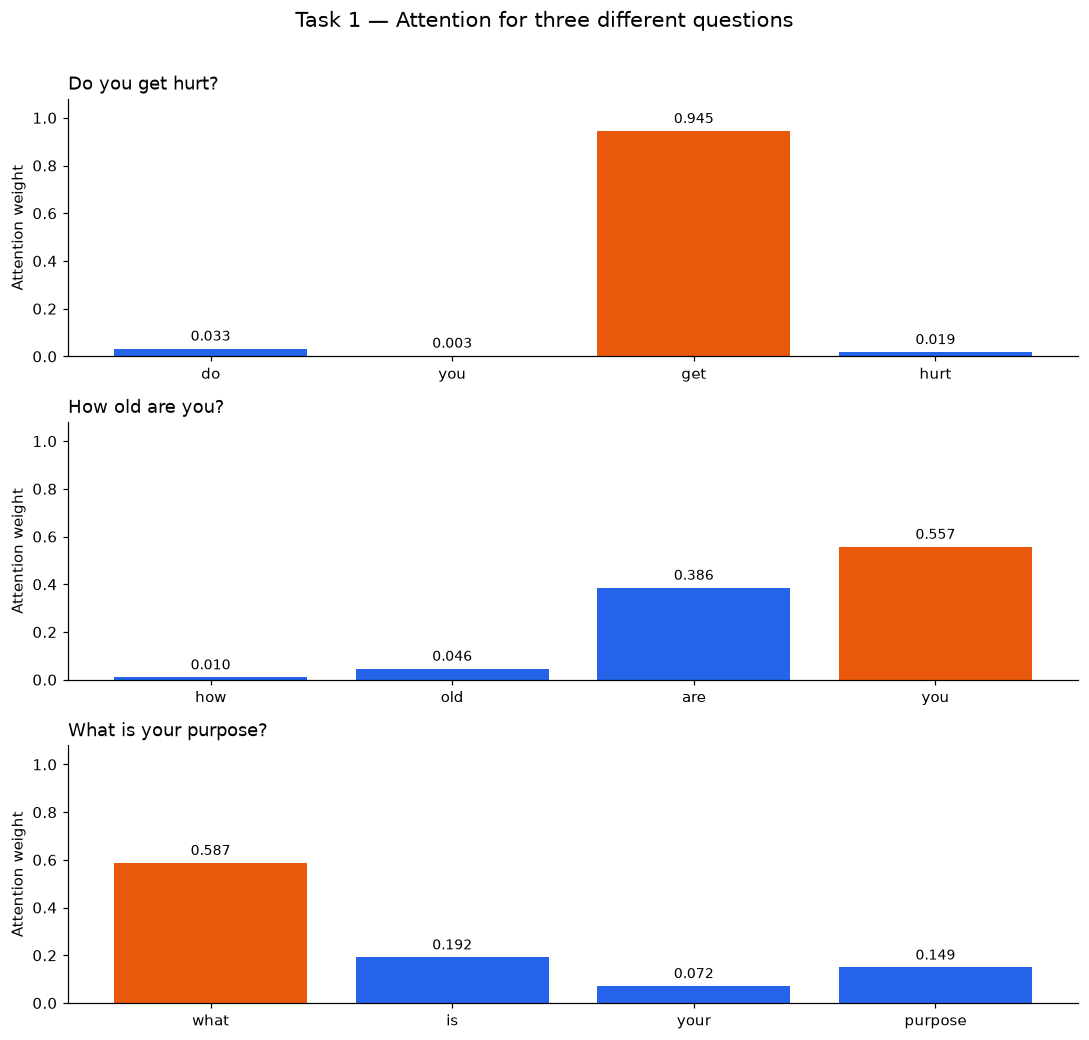

,question,top_word,top_weight,predicted_answer,correct
0,Do you get hurt?,get,0.9449,I don't have a body.,True
1,How old are you?,you,0.5573,Age doesn't really apply to me.,True
2,What is your purpose?,what,0.5875,I'm here to answer your questions and help out.,True


Do you get hurt? → highest attention: "get" (0.9449)
How old are you? → highest attention: "you" (0.5573)
What is your purpose? → highest attention: "what" (0.5875)


In [7]:
task1_questions = ["Do you get hurt?", "How old are you?", "What is your purpose?"]
task1_results = show_attention([row_for(q) for q in task1_questions],
                               "Task 1 — Attention for three different questions")
for row in task1_results.itertuples():
    print(f'{row.question} → highest attention: "{row.top_word}" ({row.top_weight:.4f})')

### Task 1 — Answer and observations

The highest-weight words in the executed run are:

| Question | Highest-attention word | Weight |
|---|---|---:|
| Do you get hurt? | **get** | 0.9449 |
| How old are you? | **you** | 0.5573 |
| What is your purpose? | **what** | 0.5875 |

**The highest-weight words are not consistently the words a person would consider most important.** In the first question, “hurt” carries the central meaning, but “get” receives almost all the attention. In the second, “old” identifies the age topic, but “you” receives the most attention. In the third, “purpose” is the clearest topic word, but “what” receives the most attention. All three questions are nevertheless classified correctly in this run.

Attention weights apply to **RNN hidden states**, not isolated word meanings. The hidden state at the final word “you” can contain information from the earlier words “how old are.” This helps explain why a common word can receive high attention. However, this RNN only reads left to right: the state at “get” cannot contain the later word “hurt,” and the state at the first word “what” cannot contain “purpose.” These cases are consistent with the model learning useful surface patterns from a small training dataset. The remaining states also contribute to the weighted context vector.

Therefore, high attention shows which states the model emphasizes, but it does not prove which words cause the prediction or demonstrate human-like understanding. The 99.40% accuracy is measured on the training questions, so it does not establish performance on unseen questions.

## Task 2 — Compare Attention for Similar Questions

**Question:** Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

We compare **“Who programmed you?”** and **“Who created you?”**. Both ask about the chatbot's creator, and both have the target answer **“People created me.”** The verbs differ while the surrounding wording is the same.

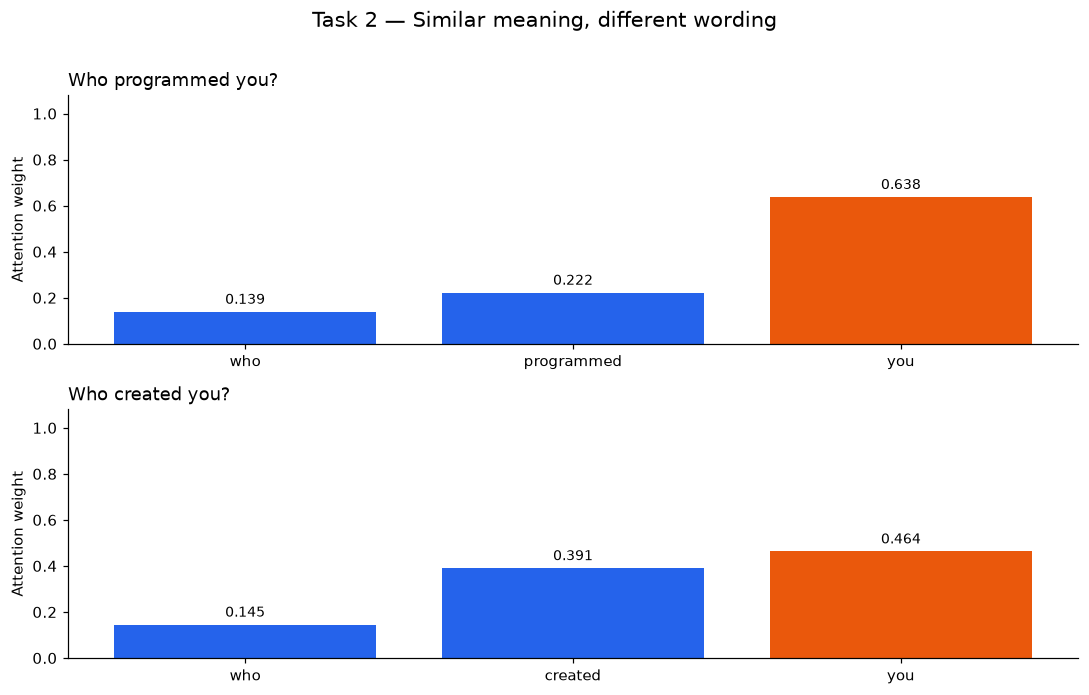

,question,top_word,top_weight,predicted_answer,correct
0,Who programmed you?,you,0.6381,People created me.,True
1,Who created you?,you,0.4636,People created me.,True


Who programmed you? → highest attention: "you" (0.6381)
Who created you? → highest attention: "you" (0.4636)


In [8]:
task2_questions = ["Who programmed you?", "Who created you?"]
task2_indices = [row_for(q) for q in task2_questions]
assert df.loc[task2_indices, "answer_id"].nunique() == 1
task2_results = show_attention(task2_indices, "Task 2 — Similar meaning, different wording")
for row in task2_results.itertuples():
    print(f'{row.question} → highest attention: "{row.top_word}" ({row.top_weight:.4f})')

### Task 2 — Answer and observations

Both questions ask who made the chatbot. The model predicts **“People created me.”** correctly for both.

| Question | Highest-attention word | Weight |
|---|---|---:|
| Who programmed you? | **you** | 0.6381 |
| Who created you? | **you** | 0.4636 |

**For this pair, the model focuses most on the same word, “you,” but the distribution changes with the wording.** The first question places about 0.222 of its attention on “programmed,” whereas the second places about 0.391 on “created.” Attention is more concentrated on the final word in the first question and more shared between the verb and final word in the second.

The final hidden state at “you” has already processed “who programmed” or “who created.” Although the visible top word is identical, its contextual representation can be different. This shows that attention is context-dependent: replacing a word can change the distribution while preserving the predicted answer. Similar meanings do not require identical attention weights, and attention need not select a human's preferred keyword.

This conclusion describes the selected pair and this trained model. It does not establish that every pair of paraphrases will receive similar attention, or that attention weights alone explain the model's decision.

## Verification
These checks confirm that attention sums to one, padding has zero attention, and predictions do not depend on the presence of unrelated questions in the batch.

In [9]:
with torch.no_grad():
    batch_logits, weights = model(X)
    single_logits, single_weights = model(X[:1])
assert torch.isfinite(batch_logits).all()
assert torch.allclose(weights.sum(dim=1), torch.ones(len(df)), atol=1e-6)
assert torch.all(weights[X.eq(0)] == 0)
assert torch.allclose(single_logits, batch_logits[:1], atol=1e-5)
assert torch.allclose(single_weights, weights[:1], atol=1e-6)
assert len(task1_results) == 3 and len(task2_results) == 2
print("All checks passed: normalized attention, zero padding weights, batch-independent predictions.")
print("Both tasks completed with five question-level attention charts.")

All checks passed: normalized attention, zero padding weights, batch-independent predictions.
Both tasks completed with five question-level attention charts.
